# Workstream 4: Issue [L5] — Jacobian Lens (Matteo)

Notebook for developing, validating, and benchmarking the **Jacobian Lens** (training-free, first-order lens) for autoregressive decoders (**GPT-2** and **GePpeTto**) before porting the code into `src/ws4_lens/jacobian_lens.py`, `scripts/33_estimate_jacobians.py`, and `tests/test_jacobian_lens.py`.

---

### Contract Specifications (`docs/CONTRACTS.md` Sections 9.2, 9.5, 10 & Issue #23)
- **Definition (Team definition, training-free, aligned with Gurnee et al. 2026 corpus-averaged Jacobian map)**:
  $$J_l = \mathbb{E}_{t}\!\left[\frac{\partial r_L(t)}{\partial h_l(t)}\right] \in \mathbb{R}^{d \times d}$$
  where $r_L(t)$ is the output of the **last transformer block before `ln_f`** (captured via a forward hook on `model.transformer.h[-1]`; Hugging Face `hidden_states[L]` is *after* `ln_f` and cannot be used).
- **Same-position Jacobian**: For each sampled position $t$, other positions $s \neq t$ are held fixed.
- **Layer $L$**: $J_L = I_d$ (exact identity).
- **Projection (`jacobian_lens`)**:
  - For $l < L$: $\text{logits}_l = W_U(\text{LN}_f(h_l J_l^\top))$
  - For $l = L$: $\text{logits}_L = W_U(h_L)$ (exact match with `model(...).logits`).
- **Calibration splits** (never test!):
  - `geppetto`: **ISDT train** (encoded via `encode_words(..., add_bos=True)`).
  - `gpt2`: **WikiText-103 train** (256-token non-overlapping windows).
- **Checkpoints**: `checkpoints/jacobian_lens/{model}.pt` containing a `float32` tensor of shape `[L + 1, d, d]`.
- **Edge cases**:
  - Always compute in `float32` (never `float16`).
  - `model.eval()` so dropout is strictly off.
  - Exclude BOS and padding positions when sampling with `np.random.default_rng(seed)`.

## 1. Environment Setup and Imports

In [1]:
import gc
import sys
import time
from collections.abc import Iterable
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

# Locate repository root and add src/ to sys.path
cwd = Path.cwd().resolve()
ROOT_DIR = cwd if (cwd / "src").exists() else cwd.parent
SRC_DIR = ROOT_DIR / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from lib.alignment import encode_words
from lib.data import load_model
from lib.paths import ROOT
from lib.registry import get_model_spec
from lib.word_table import load_word_table, table_to_sentences
from ws4_lens.logit_lens import _get_lens_components, logit_lens, run_model
from ws4_lens.metrics import kl_to_final

print(f"Repository root: {ROOT}")
print(f"PyTorch version: {torch.__version__}")
print(f"MPS available:   {torch.backends.mps.is_available()}")
print(f"CUDA available:  {torch.cuda.is_available()}")

/Users/matteosalvini/Desktop/Magistrale/HLT/HLT_Project-LLMs_on_Probing_and_Logit_Lens/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository root: /Users/matteosalvini/Desktop/Magistrale/HLT/HLT_Project-LLMs_on_Probing_and_Logit_Lens
PyTorch version: 2.15.0
MPS available:   True
CUDA available:  False


## 2. Implementation of `estimate_jacobians`, `jacobian_lens`, and Checkpoint Helpers

### Key Implementation Details
1. **Frozen Model Gradients**: All model weights stay frozen (`param.requires_grad = False`). We attach a temporary forward hook on `model.transformer.drop` returning `out.detach().requires_grad_(True)` so that `h_0 .. h_{L-1}` and `r_L` form an active autograd graph without ever computing parameter gradients.
2. **Pre-LN Final Residual Stream (`r_L`)**: Captured via a forward hook on `model.transformer.h[-1]`.
3. **Batched Row-Chunked Autograd**: For each sampled position `t`, we differentiate `r_L[0, t]` against `[h_0, ..., h_{L-1}]` in chunks of rows of the identity matrix $I_d$ using `torch.autograd.grad(..., grad_outputs=basis_chunk, is_grads_batched=True)` and slice only position `t`.
4. **Exact Causal Truncation & Memory Safety (8 GB Mac)**: Because GPT-2 / GePpeTto use causal attention, `r_L[t]` and its Jacobian depend **only** on tokens `0 .. t`. Truncating each sampled sequence to `0 .. t` yields the bit-for-bit identical Jacobian while slashing $O(T^2)$ attention cost. On MPS, for long prefixes (`t >= 128`), we also cap the internal autograd chunk size to avoid macOS unified-memory swapping (mathematically identical result).

In [2]:
def _get_jacobian_modules(model: nn.Module) -> tuple[nn.Module, nn.Module]:
    """Locate the embedding-dropout entry module and the final transformer block.

    Parameters
    ----------
    model : nn.Module
        Causal decoder model (e.g. GPT2LMHeadModel).

    Returns
    -------
    tuple[nn.Module, nn.Module]
        Pair of (entry_module, last_block), where `entry_module` produces
        `hidden_states[0]` and `last_block` produces `r_L` before `ln_f`.
    """
    if hasattr(model, "transformer") and hasattr(model.transformer, "h"):
        blocks = model.transformer.h
        entry = getattr(model.transformer, "drop", None)
    elif hasattr(model, "h"):
        blocks = model.h
        entry = getattr(model, "drop", None)
    else:
        raise AttributeError(
            f"Could not locate transformer blocks (transformer.h) on {type(model).__name__}."
        )

    if len(blocks) == 0:
        raise ValueError("Model transformer block list is empty.")
    if entry is None:
        raise AttributeError(
            f"Could not locate embedding dropout module (transformer.drop) on {type(model).__name__}."
        )

    return entry, blocks[-1]


def _check_float32_model(model: nn.Module) -> None:
    """Verify that model parameters are in float32 (never float16/bfloat16)."""
    for param in model.parameters():
        if param.dtype in (torch.float16, torch.bfloat16):
            raise ValueError(
                f"Jacobian estimation must be computed in float32, never {param.dtype}. "
                "Convert the model to float32 before calling estimate_jacobians."
            )
        break


def estimate_jacobians(
    model: nn.Module,
    batches: Iterable[tuple[torch.Tensor, torch.Tensor]],
    *,
    n_positions: int = 512,
    seed: int = 42,
    chunk_size: int = 64,
    verbose: bool = True,
) -> torch.Tensor:
    """Estimate mean per-layer same-position Jacobians J_l = E[d r_L(t) / d h_l(t)].

    Parameters
    ----------
    model : nn.Module
        Frozen causal decoder model in float32.
    batches : Iterable[tuple[torch.Tensor, torch.Tensor]]
        Iterable yielding `(input_ids, attention_mask)` batches of shape `[B, T]`.
    n_positions : int, default=512
        Number of valid non-BOS, non-padding positions to sample and average.
    seed : int, default=42
        Random seed for `numpy.random.default_rng(seed)`.
    chunk_size : int, default=64
        Number of identity basis rows per batched `torch.autograd.grad` call.
    verbose : bool, default=True
        Whether to log progress and time per position.

    Returns
    -------
    torch.Tensor
        Float32 CPU tensor of shape `[L + 1, d, d]` with exact identity at `J[L]`.
    """
    if n_positions <= 0:
        raise ValueError(f"n_positions must be positive, got {n_positions}.")
    if chunk_size <= 0:
        raise ValueError(f"chunk_size must be positive, got {chunk_size}.")

    _check_float32_model(model)
    model.eval()

    try:
        device = next(model.parameters()).device
    except StopIteration:
        device = torch.device("cpu")

    entry_module, last_block = _get_jacobian_modules(model)
    bos_token_id = getattr(getattr(model, "config", None), "bos_token_id", None)

    # 1. Materialize CPU token batches and collect all valid (batch_idx, b, t) positions
    stored_batches: list[tuple[torch.Tensor, torch.Tensor]] = []
    candidates: list[tuple[int, int, int]] = []

    for batch_idx, (input_ids, attention_mask) in enumerate(batches):
        ids_cpu = input_ids.detach().to("cpu")
        mask_cpu = attention_mask.detach().to("cpu")
        stored_batches.append((ids_cpu, mask_cpu))

        valid = mask_cpu == 1
        # Exclude position 0 (BOS or zero-context position)
        valid[:, 0] = False
        # Exclude explicit BOS tokens anywhere in the sequence
        if bos_token_id is not None:
            valid &= ids_cpu != bos_token_id

        coords = valid.nonzero(as_tuple=False)
        for b_val, t_val in coords.tolist():
            candidates.append((batch_idx, b_val, t_val))

    total_valid = len(candidates)
    if total_valid == 0:
        raise ValueError("No valid non-BOS, non-padding positions found in batches.")

    k = min(n_positions, total_valid)
    rng = np.random.default_rng(seed)
    chosen_indices = rng.choice(total_valid, size=k, replace=False)
    sampled_positions = [candidates[int(idx)] for idx in chosen_indices]

    # Resolve L and d
    num_layers = getattr(model.config, "n_layer", None) or getattr(model.config, "num_hidden_layers", None)
    hidden_size = getattr(model.config, "n_embd", None) or getattr(model.config, "hidden_size", None)
    if num_layers is None or hidden_size is None:
        raise AttributeError("Could not determine num_layers or hidden_size from model.config.")

    eye_d = torch.eye(hidden_size, device=device, dtype=torch.float32)
    j_sum = torch.zeros((num_layers + 1, hidden_size, hidden_size), device="cpu", dtype=torch.float32)

    captured_r_l: list[torch.Tensor] = []

    def _hook_entry(_module: nn.Module, _inp: tuple, out: torch.Tensor) -> torch.Tensor:
        return out.detach().requires_grad_(True)

    def _hook_last_block(_module: nn.Module, _inp: tuple, out: torch.Tensor | tuple) -> None:
        r_tensor = out[0] if isinstance(out, tuple) else out
        captured_r_l.append(r_tensor)

    t_start = time.perf_counter()
    h_entry = entry_module.register_forward_hook(_hook_entry)
    h_last = last_block.register_forward_hook(_hook_last_block)

    try:
        for pos_num, (batch_idx, b_idx, t_idx) in enumerate(sampled_positions, start=1):
            ids_cpu, mask_cpu = stored_batches[batch_idx]
            # Exact causal truncation to 0..t_idx (tokens > t_idx cannot affect r_L[t_idx])
            seq_ids = ids_cpu[b_idx : b_idx + 1, : t_idx + 1].to(device)
            seq_mask = mask_cpu[b_idx : b_idx + 1, : t_idx + 1].to(device)
            seq_len = t_idx + 1

            captured_r_l.clear()
            with torch.enable_grad():
                outputs = model(
                    input_ids=seq_ids,
                    attention_mask=seq_mask,
                    output_hidden_states=True,
                )
                hidden_states = list(outputs.hidden_states[:-1])  # h_0 .. h_{L-1}
                if len(hidden_states) != num_layers:
                    raise RuntimeError(
                        f"Expected {num_layers} pre-final hidden states, got {len(hidden_states)}."
                    )
                if not captured_r_l:
                    raise RuntimeError("Forward hook on last transformer block did not capture r_L.")
                r_l_vec = captured_r_l[0][0, t_idx, :].float()  # [d]

                # Adaptive chunk size on MPS for long prefixes to avoid 8GB RAM swap
                eff_chunk = chunk_size
                if device.type == "mps" and seq_len > 128:
                    eff_chunk = min(chunk_size, 16)
                elif device.type == "mps" and seq_len > 64:
                    eff_chunk = min(chunk_size, 32)

                for start in range(0, hidden_size, eff_chunk):
                    end = min(start + eff_chunk, hidden_size)
                    basis_chunk = eye_d[start:end]  # [C, d]
                    retain = end < hidden_size
                    grads = torch.autograd.grad(
                        r_l_vec,
                        hidden_states,
                        grad_outputs=basis_chunk,
                        is_grads_batched=True,
                        retain_graph=retain,
                    )
                    for layer_idx, g in enumerate(grads):
                        # g has shape [C, 1, seq_len, d]; keep only position t_idx
                        j_sum[layer_idx, start:end, :] += g[:, 0, t_idx, :].detach().to("cpu", dtype=torch.float32)

            del outputs, hidden_states, r_l_vec, seq_ids, seq_mask
            captured_r_l.clear()

            if pos_num % 16 == 0:
                if device.type == "mps" and hasattr(torch, "mps"):
                    torch.mps.empty_cache()
                elif device.type == "cuda" and torch.cuda.is_available():
                    torch.cuda.empty_cache()

            if verbose and (pos_num == 1 or pos_num % max(1, k // 8) == 0 or pos_num == k):
                if device.type == "mps" and hasattr(torch, "mps"):
                    torch.mps.synchronize()
                elapsed = time.perf_counter() - t_start
                print(
                    f"  Position {pos_num:>4}/{k} | Elapsed: {elapsed:>7.2f}s | "
                    f"Avg: {elapsed / pos_num:.3f}s/pos | Last prefix len: {seq_len}"
                )
    finally:
        h_entry.remove()
        h_last.remove()
        if device.type == "mps" and hasattr(torch, "mps"):
            torch.mps.empty_cache()
        elif device.type == "cuda" and torch.cuda.is_available():
            torch.cuda.empty_cache()

    j_mean = j_sum / float(k)
    j_mean[num_layers] = torch.eye(hidden_size, dtype=torch.float32)

    total_time = time.perf_counter() - t_start
    if verbose:
        print(
            f"Done! Estimated Jacobians [{num_layers + 1}, {hidden_size}, {hidden_size}] "
            f"over {k} positions in {total_time:.2f}s ({total_time / k:.3f}s/pos)."
        )
    return j_mean


def jacobian_lens(
    model: nn.Module,
    jacobians: torch.Tensor,
    hidden_states: list[torch.Tensor],
) -> list[torch.Tensor]:
    """Compute Jacobian Lens logits across all layers 0 .. L.

    For layers l < L:
        logits_l = lm_head(ln_f(h_l @ J_l.T))
    For final layer l = L:
        logits_L = lm_head(h_L)  (matches model(...).logits bit-for-bit)

    Parameters
    ----------
    model : nn.Module
        Causal decoder model with accessible ln_f and lm_head.
    jacobians : torch.Tensor
        Tensor of shape `[L + 1, d, d]` from `estimate_jacobians`.
    hidden_states : list[torch.Tensor]
        List of `L + 1` hidden state tensors of shape `[B, T, d]`.

    Returns
    -------
    list[torch.Tensor]
        List of `L + 1` logit tensors of shape `[B, T, V]`.
    """
    if not hidden_states:
        raise ValueError("hidden_states list must not be empty.")
    if jacobians.ndim != 3:
        raise ValueError(f"jacobians must be a 3D tensor [L + 1, d, d], got shape {tuple(jacobians.shape)}.")
    if jacobians.shape[0] != len(hidden_states):
        raise ValueError(
            f"Number of Jacobian matrices ({jacobians.shape[0]}) does not match "
            f"len(hidden_states) ({len(hidden_states)})."
        )

    hidden_size = hidden_states[0].shape[-1]
    if jacobians.shape[1] != hidden_size or jacobians.shape[2] != hidden_size:
        raise ValueError(
            f"Jacobian matrix dimensions {tuple(jacobians.shape[1:])} do not match "
            f"hidden_size {hidden_size}."
        )

    ln_f, lm_head = _get_lens_components(model)
    num_layers = len(hidden_states) - 1
    logits: list[torch.Tensor] = []

    with torch.no_grad():
        for layer_idx, h in enumerate(hidden_states):
            if layer_idx < num_layers:
                j_l = jacobians[layer_idx].to(device=h.device, dtype=torch.float32)
                h_proj = torch.matmul(h.float(), j_l.T).to(dtype=h.dtype)
                logits_l = lm_head(ln_f(h_proj))
            else:
                logits_l = lm_head(h)
            logits.append(logits_l)

    return logits


def save_jacobian_checkpoint(
    jacobians: torch.Tensor,
    model_name: str,
    output_dir: str | Path = "checkpoints/jacobian_lens",
) -> Path:
    """Save Jacobian tensor `[L + 1, d, d]` per CONTRACTS.md Section 9.5."""
    out_path = Path(output_dir)
    if not out_path.is_absolute():
        out_path = ROOT / out_path
    out_path.mkdir(parents=True, exist_ok=True)
    pt_path = out_path / f"{model_name}.pt"
    torch.save(jacobians.detach().to("cpu", dtype=torch.float32), pt_path)
    return pt_path


def load_jacobian_checkpoint(
    model_name: str,
    checkpoint_dir: str | Path = "checkpoints/jacobian_lens",
) -> torch.Tensor:
    """Load Jacobian tensor `[L + 1, d, d]` from checkpoint directory."""
    p_dir = Path(checkpoint_dir)
    if not p_dir.is_absolute() and not (p_dir / f"{model_name}.pt").exists():
        if (ROOT / p_dir / f"{model_name}.pt").exists():
            p_dir = ROOT / p_dir
    pt_path = p_dir / f"{model_name}.pt"
    if not pt_path.exists():
        raise FileNotFoundError(f"Jacobian checkpoint not found at: {pt_path}")
    return torch.load(pt_path, map_location="cpu", weights_only=True)

## 3. Unit Verification & Finite-Difference Sanity Check (Tiny Random GPT-2)

Verifies all Issue #23 acceptance criteria on a tiny random GPT-2 (`L=3, d=16`):
1. `J_L` is the exact identity matrix $I_d$.
2. Entries of `J_l` match central finite differences $\frac{r_L(h_l + \varepsilon e_j) - r_L(h_l - \varepsilon e_j)}{2\varepsilon}$ with relative error $< 10^{-3}$.
3. `jacobian_lens(model, J, hidden_states)[-1]` matches `model(...).logits` bit-for-bit.
4. Setting all `J_l = I` matches `logit_lens` identically.

In [3]:
from transformers import GPT2Config, GPT2LMHeadModel

torch.manual_seed(42)
tiny_cfg = GPT2Config(
    vocab_size=50,
    n_positions=32,
    n_embd=16,
    n_layer=3,
    n_head=2,
    bos_token_id=0,
    eos_token_id=0,
)
tiny_model = GPT2LMHeadModel(tiny_cfg).eval()
for p in tiny_model.parameters():
    p.requires_grad_(False)

input_ids_fd = torch.tensor([[0, 5, 12, 23, 7]])  # pos 0 is BOS=0
attn_mask_fd = torch.ones_like(input_ids_fd)

# Determine the exact position rng(42) picks from valid positions [1, 2, 3, 4]
rng_check = np.random.default_rng(42)
picked_t = [1, 2, 3, 4][int(rng_check.choice(4, size=1, replace=False)[0])]
print(f"Tiny GPT-2 finite-difference check at sampled position t = {picked_t}")

J_tiny = estimate_jacobians(
    tiny_model,
    [(input_ids_fd, attn_mask_fd)],
    n_positions=1,
    seed=42,
    chunk_size=8,
    verbose=False,
)

# 1. Check shape and J_L == I
assert J_tiny.shape == (4, 16, 16), f"Unexpected shape: {J_tiny.shape}"
assert J_tiny.dtype == torch.float32
assert torch.allclose(J_tiny[-1], torch.eye(16), atol=1e-7), "J_L is not identity!"
print("✅ Test 1 PASSED: shape == [L+1, d, d] and J_L == I")

# 2. Central finite difference check across EVERY layer l = 0, 1, 2
eps = 1e-4
i_idx, j_idx = 5, 7
for layer_idx in range(3):
    def eval_r_l_entry(delta: float) -> float:
        captured = []
        def perturb_hook(_m, args):
            h = args[0].clone()
            h[0, picked_t, j_idx] += delta
            return (h,) + args[1:]
        def cap_hook(_m, _inp, out):
            captured.append((out[0] if isinstance(out, tuple) else out).detach())
        p_h = tiny_model.transformer.h[layer_idx].register_forward_pre_hook(perturb_hook)
        c_h = tiny_model.transformer.h[-1].register_forward_hook(cap_hook)
        with torch.no_grad():
            tiny_model(input_ids=input_ids_fd, attention_mask=attn_mask_fd)
        p_h.remove()
        c_h.remove()
        return captured[0][0, picked_t, i_idx].item()

    fd_val = (eval_r_l_entry(+eps) - eval_r_l_entry(-eps)) / (2.0 * eps)
    auto_val = J_tiny[layer_idx, i_idx, j_idx].item()
    rel_err = abs(fd_val - auto_val) / max(abs(fd_val), abs(auto_val), 1e-8)
    print(f"   Layer {layer_idx}: autograd={auto_val:+.6f}, finite_diff={fd_val:+.6f}, rel_err={rel_err:.2e}")
    assert rel_err < 1e-3, f"Relative error too high at layer {layer_idx}: {rel_err}"
print("✅ Test 2 PASSED: Autograd Jacobian matches finite differences (rel_err < 1e-3) on all layers!")

# 3. Check jacobian_lens layer L equals model logits
hs_tiny = run_model(tiny_model, input_ids_fd, attn_mask_fd)
j_logits = jacobian_lens(tiny_model, J_tiny, hs_tiny)
with torch.no_grad():
    official_logits = tiny_model(input_ids=input_ids_fd, attention_mask=attn_mask_fd).logits
max_diff_L = (j_logits[-1] - official_logits).abs().max().item()
assert torch.allclose(j_logits[-1], official_logits, atol=1e-5)
print(f"✅ Test 3 PASSED: jacobian_lens layer L equals model logits (max diff: {max_diff_L:.2e})")

# 4. Identity Jacobians equal Standard Logit Lens
J_eye = torch.eye(16).unsqueeze(0).repeat(4, 1, 1)
j_eye_logits = jacobian_lens(tiny_model, J_eye, hs_tiny)
l_logits = logit_lens(tiny_model, hs_tiny)
max_eye_diff = max((a - b).abs().max().item() for a, b in zip(j_eye_logits, l_logits))
assert max_eye_diff < 1e-5
print(f"✅ Test 4 PASSED: Identity Jacobians match Standard Logit Lens (max diff: {max_eye_diff:.2e})")

W1117 22:46:32.358000 19860 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Tiny GPT-2 finite-difference check at sampled position t = 1
✅ Test 1 PASSED: shape == [L+1, d, d] and J_L == I
   Layer 0: autograd=+0.034801, finite_diff=+0.034806, rel_err=1.53e-04
   Layer 1: autograd=+0.026752, finite_diff=+0.026750, rel_err=9.62e-05
   Layer 2: autograd=+0.024894, finite_diff=+0.024897, rel_err=9.49e-05
✅ Test 2 PASSED: Autograd Jacobian matches finite differences (rel_err < 1e-3) on all layers!
✅ Test 3 PASSED: jacobian_lens layer L equals model logits (max diff: 0.00e+00)
✅ Test 4 PASSED: Identity Jacobians match Standard Logit Lens (max diff: 0.00e+00)


## 4. Calibration Data Builders & 50-Sequence KL Evaluation Helper

- **GePpeTto calibration split**: `isdt_train` (from `load_word_table("isdt", "train")`, encoded with `encode_words(..., add_bos=True)`).
- **GPT-2 calibration split**: `wikitext-103-raw-v1` `train` split (streamed into 256-token non-overlapping windows so we do not download 500 MB unnecessarily).
- **Evaluation helper**: Computes per-layer mean KL divergence $D_{\text{KL}}(P_L \parallel P_l)$ on 50 calibration-split sequences for both Logit Lens and Jacobian Lens and prints the Markdown table required in Issue #23.

In [4]:
def build_isdt_calibration_batches(
    tokenizer,
    *,
    batch_size: int = 8,
    max_length: int = 128,
) -> list[tuple[torch.Tensor, torch.Tensor]]:
    """Load ISDT train word table and encode into (input_ids, attention_mask) batches."""
    train_table = load_word_table("isdt", "train")
    sentences = table_to_sentences(train_table)
    batches: list[tuple[torch.Tensor, torch.Tensor]] = []
    for i in range(0, len(sentences), batch_size):
        batch_words = [words for _, words in sentences[i : i + batch_size]]
        encoded, _ = encode_words(tokenizer, batch_words, add_bos=True, max_length=max_length)
        batches.append((encoded["input_ids"], encoded["attention_mask"]))
    return batches


def build_wikitext_calibration_batches(
    tokenizer,
    *,
    window_size: int = 256,
    max_windows: int = 200,
    batch_size: int = 4,
) -> list[tuple[torch.Tensor, torch.Tensor]]:
    """Stream WikiText-103 train into non-overlapping 256-token windows."""
    from datasets import load_dataset

    ds = load_dataset(
        "Salesforce/wikitext",
        "wikitext-103-raw-v1",
        split="train",
        streaming=True,
    )
    target_tokens = window_size * max_windows
    token_buf: list[int] = []
    for row in ds:
        text = row["text"].strip()
        if not text:
            continue
        ids = tokenizer.encode(text, add_special_tokens=False)
        token_buf.extend(ids)
        if len(token_buf) >= target_tokens:
            break

    n_win = min(max_windows, len(token_buf) // window_size)
    windows = [
        torch.tensor(token_buf[i * window_size : (i + 1) * window_size], dtype=torch.long)
        for i in range(n_win)
    ]

    batches: list[tuple[torch.Tensor, torch.Tensor]] = []
    for i in range(0, len(windows), batch_size):
        chunk = torch.stack(windows[i : i + batch_size], dim=0)
        mask = torch.ones_like(chunk)
        batches.append((chunk, mask))
    return batches


@torch.no_grad()
def evaluate_jacobian_vs_logit_kl(
    model: nn.Module,
    jacobians: torch.Tensor,
    batches: list[tuple[torch.Tensor, torch.Tensor]],
    *,
    n_sequences: int = 50,
    title: str = "Calibration Split",
) -> tuple[list[float], list[float]]:
    """Compare per-layer mean KL(P_L || P_l) of Logit Lens vs Jacobian Lens on `n_sequences`.

    Evaluates 1 sequence at a time and projects layer-by-layer to keep peak MPS/GPU
    memory tiny even on 256-token WikiText windows with V=50,257.
    """
    model.eval()
    ln_f, lm_head = _get_lens_components(model)
    num_layers = jacobians.shape[0] - 1
    logit_kl_sums = torch.zeros(num_layers + 1, dtype=torch.float64)
    jac_kl_sums = torch.zeros(num_layers + 1, dtype=torch.float64)
    total_positions = 0
    seen_seqs = 0

    for input_ids, attention_mask in batches:
        if seen_seqs >= n_sequences:
            break
        batch_size = input_ids.shape[0]
        for s_idx in range(batch_size):
            if seen_seqs >= n_sequences:
                break
            ids = input_ids[s_idx : s_idx + 1]
            mask = attention_mask[s_idx : s_idx + 1]

            hidden_states = run_model(model, ids, mask)
            # Next-token prediction positions 0 .. T-2 (skip last position per CONTRACTS.md 9.1)
            valid_mask = (mask[:, :-1] == 1).to(hidden_states[-1].device)
            n_valid = int(valid_mask.sum().item())
            if n_valid == 0:
                continue

            final_h = hidden_states[-1][:, :-1, :][valid_mask]
            final_logits = lm_head(final_h)

            for layer_idx in range(num_layers + 1):
                h_pos = hidden_states[layer_idx][:, :-1, :][valid_mask]
                if layer_idx < num_layers:
                    l_pos = lm_head(ln_f(h_pos))
                    j_l = jacobians[layer_idx].to(device=h_pos.device, dtype=torch.float32)
                    j_pos = lm_head(ln_f(torch.matmul(h_pos.float(), j_l.T).to(dtype=h_pos.dtype)))
                else:
                    l_pos = final_logits
                    j_pos = final_logits

                logit_kl_sums[layer_idx] += kl_to_final(l_pos, final_logits).detach().cpu().double().sum().item()
                jac_kl_sums[layer_idx] += kl_to_final(j_pos, final_logits).detach().cpu().double().sum().item()

            del hidden_states, final_h, final_logits
            total_positions += n_valid
            seen_seqs += 1

        if torch.backends.mps.is_available():
            torch.mps.empty_cache()
        elif torch.cuda.is_available():
            torch.cuda.empty_cache()

    mean_logit = (logit_kl_sums / max(total_positions, 1)).tolist()
    mean_jac = (jac_kl_sums / max(total_positions, 1)).tolist()

    print(f"\n### {title} — Per-Layer KL to Final ({seen_seqs} sequences, {total_positions:,} positions)\n")
    print(f"| {'Layer':<5} | {'Logit Lens KL':<13} | {'Jacobian Lens KL':<16} | {'Reduction (%)':<13} |")
    print(f"|{'-'*7}|{'-'*15}|{'-'*18}|{'-'*15}|")
    for layer_idx in range(num_layers + 1):
        kl_l = mean_logit[layer_idx]
        kl_j = mean_jac[layer_idx]
        red = ((kl_l - kl_j) / kl_l * 100.0) if kl_l > 1e-12 else 0.0
        print(f"| {layer_idx:<5} | {kl_l:<13.4f} | {kl_j:<16.4f} | {red:>11.2f}%  |")

    return mean_logit, mean_jac

## 5. GePpeTto Jacobian Estimation (ISDT Train)

1. Load **GePpeTto** (`LorenzoDeMattei/GePpeTto`) via `lib.data.load_model` (`add_prefix_space=True`).
2. Start with `N_POSITIONS_GEPPETTO = 128` to measure time per position (can be increased to `512` once timing is verified).
3. Save to `checkpoints/jacobian_lens/geppetto.pt` (skipped if checkpoint already exists unless `FORCE_RECOMPUTE_GEPPETTO = True`).
4. Evaluate per-layer KL on 50 ISDT train sequences vs Standard Logit Lens and run a qualitative demo.

In [5]:
N_POSITIONS_GEPPETTO = 128  # Start with 128 to measure time; increase to 512 for final checkpoint
FORCE_RECOMPUTE_GEPPETTO = False

spec_it = get_model_spec("geppetto")
model_it, tokenizer_it, meta_it = load_model(
    checkpoint=spec_it["hf_id"],
    kind=spec_it["kind"],
    tokenizer_kwargs={"add_prefix_space": True},
)
print(f"Loaded GePpeTto on device: {meta_it['device']}")

isdt_batches = build_isdt_calibration_batches(tokenizer_it, batch_size=8, max_length=128)
print(f"Built {len(isdt_batches):,} ISDT train calibration batches.")

geppetto_ckpt = ROOT / "checkpoints" / "jacobian_lens" / "geppetto.pt"
if geppetto_ckpt.exists() and not FORCE_RECOMPUTE_GEPPETTO:
    print(f"Loading existing Jacobian checkpoint from {geppetto_ckpt}...")
    J_geppetto = load_jacobian_checkpoint("geppetto")
else:
    print(f"Estimating GePpeTto Jacobians over n_positions={N_POSITIONS_GEPPETTO}...")
    J_geppetto = estimate_jacobians(
        model_it,
        isdt_batches,
        n_positions=N_POSITIONS_GEPPETTO,
        seed=42,
        chunk_size=64,
        verbose=True,
    )
    saved_path = save_jacobian_checkpoint(J_geppetto, "geppetto")
    print(f"Saved GePpeTto Jacobian checkpoint to: {saved_path}")

assert torch.allclose(J_geppetto[-1], torch.eye(spec_it["hidden_size"]), atol=1e-7)
print(f"J_geppetto shape: {tuple(J_geppetto.shape)}, dtype: {J_geppetto.dtype} (J_L == I verified ✅)")

[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 29999), got 50256. This may result in unexpected behavior.
[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Loading weights: 100%|██████████| 148/148 [00:00<00:00, 2974.28it/s]


Loaded GePpeTto on device: mps


Truncated 1 sentence(s) to max_length=128; 33 word(s) lost all their subwords and get NaN rows.
Truncated 1 sentence(s) to max_length=128; 7 word(s) lost all their subwords and get NaN rows.
Truncated 2 sentence(s) to max_length=128; 243 word(s) lost all their subwords and get NaN rows.
Truncated 1 sentence(s) to max_length=128; 11 word(s) lost all their subwords and get NaN rows.
Truncated 3 sentence(s) to max_length=128; 244 word(s) lost all their subwords and get NaN rows.
Truncated 1 sentence(s) to max_length=128; 3 word(s) lost all their subwords and get NaN rows.


Built 1,641 ISDT train calibration batches.
Loading existing Jacobian checkpoint from /Users/matteosalvini/Desktop/Magistrale/HLT/HLT_Project-LLMs_on_Probing_and_Logit_Lens/checkpoints/jacobian_lens/geppetto.pt...
J_geppetto shape: (13, 768, 768), dtype: torch.float32 (J_L == I verified ✅)


In [6]:
# 1. Acceptance criterion: Per-layer KL on 50 calibration sequences vs Logit Lens
geppetto_kl_logit, geppetto_kl_jac = evaluate_jacobian_vs_logit_kl(
    model_it,
    J_geppetto,
    isdt_batches,
    n_sequences=50,
    title="GePpeTto (ISDT Train)",
)

# 2. Qualitative demo
prompt_it = "La capitale d'Italia è"
inputs_it = tokenizer_it(prompt_it, return_tensors="pt")
hs_it = run_model(model_it, inputs_it["input_ids"], inputs_it["attention_mask"])
l_logits_it = logit_lens(model_it, hs_it)
j_logits_it = jacobian_lens(model_it, J_geppetto, hs_it)

print(f"\nQualitative Demo — '{prompt_it}':")
print(f"{'Layer':<7} | {'Logit Lens Top-1':<18} | {'Jacobian Lens Top-1':<20}")
print("-" * 52)
for l_idx in range(len(hs_it)):
    tok_l = tokenizer_it.decode([l_logits_it[l_idx][0, -1, :].argmax().item()])
    tok_j = tokenizer_it.decode([j_logits_it[l_idx][0, -1, :].argmax().item()])
    print(f"Layer {l_idx:<2} | {repr(tok_l):<18} | {repr(tok_j):<20}")


### GePpeTto (ISDT Train) — Per-Layer KL to Final (50 sequences, 1,139 positions)

| Layer | Logit Lens KL | Jacobian Lens KL | Reduction (%) |
|-------|---------------|------------------|---------------|
| 0     | 58.1699       | 5.5695           |       90.43%  |
| 1     | 6.4184        | 5.4945           |       14.40%  |
| 2     | 4.3886        | 5.1247           |      -16.77%  |
| 3     | 3.8122        | 4.6334           |      -21.54%  |
| 4     | 3.5843        | 4.5583           |      -27.17%  |
| 5     | 3.4676        | 4.3486           |      -25.41%  |
| 6     | 3.1266        | 4.0318           |      -28.95%  |
| 7     | 2.4950        | 3.4596           |      -38.66%  |
| 8     | 1.8282        | 3.2694           |      -78.84%  |
| 9     | 1.1095        | 2.8112           |     -153.37%  |
| 10    | 0.5498        | 2.1679           |     -294.29%  |
| 11    | 0.1518        | 1.0292           |     -577.84%  |
| 12    | 0.0000        | 0.0000           |        0.00%  |



In [7]:
# Free GePpeTto from memory before loading GPT-2 (keeps RAM low on 8GB Mac)
del model_it, hs_it, l_logits_it, j_logits_it, isdt_batches
gc.collect()
if torch.backends.mps.is_available():
    torch.mps.empty_cache()
elif torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Cleared GePpeTto memory.")

Cleared GePpeTto memory.


## 6. GPT-2 Jacobian Estimation (WikiText-103 Train)

1. Load **GPT-2** (`gpt2`) via `lib.data.load_model` (`add_prefix_space=True`).
2. Stream 200 non-overlapping 256-token windows from `Salesforce/wikitext` (`wikitext-103-raw-v1`, `train` split).
3. Start with `N_POSITIONS_GPT2 = 128` to measure time per position (adaptive chunking keeps MPS memory safe on 8 GB Macs).
4. Save to `checkpoints/jacobian_lens/gpt2.pt` and compare per-layer KL on 50 WikiText train windows vs Standard Logit Lens.

In [8]:
N_POSITIONS_GPT2 = 128  # Start with 128 to measure time; increase to 512 for final checkpoint
FORCE_RECOMPUTE_GPT2 = False

spec_en = get_model_spec("gpt2")
model_en, tokenizer_en, meta_en = load_model(
    checkpoint=spec_en["hf_id"],
    kind=spec_en["kind"],
    tokenizer_kwargs={"add_prefix_space": True},
)
print(f"Loaded GPT-2 on device: {meta_en['device']}")

wikitext_batches = build_wikitext_calibration_batches(
    tokenizer_en,
    window_size=256,
    max_windows=200,
    batch_size=4,
)
print(f"Built {len(wikitext_batches)} WikiText-103 train calibration batches.")

gpt2_ckpt = ROOT / "checkpoints" / "jacobian_lens" / "gpt2.pt"
if gpt2_ckpt.exists() and not FORCE_RECOMPUTE_GPT2:
    print(f"Loading existing Jacobian checkpoint from {gpt2_ckpt}...")
    J_gpt2 = load_jacobian_checkpoint("gpt2")
else:
    print(f"Estimating GPT-2 Jacobians over n_positions={N_POSITIONS_GPT2}...")
    J_gpt2 = estimate_jacobians(
        model_en,
        wikitext_batches,
        n_positions=N_POSITIONS_GPT2,
        seed=42,
        chunk_size=64,
        verbose=True,
    )
    saved_path = save_jacobian_checkpoint(J_gpt2, "gpt2")
    print(f"Saved GPT-2 Jacobian checkpoint to: {saved_path}")

assert torch.allclose(J_gpt2[-1], torch.eye(spec_en["hidden_size"]), atol=1e-7)
print(f"J_gpt2 shape: {tuple(J_gpt2.shape)}, dtype: {J_gpt2.dtype} (J_L == I verified ✅)")

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7423.72it/s]


Loaded GPT-2 on device: mps
Built 50 WikiText-103 train calibration batches.
Loading existing Jacobian checkpoint from /Users/matteosalvini/Desktop/Magistrale/HLT/HLT_Project-LLMs_on_Probing_and_Logit_Lens/checkpoints/jacobian_lens/gpt2.pt...
J_gpt2 shape: (13, 768, 768), dtype: torch.float32 (J_L == I verified ✅)


In [9]:
# 1. Acceptance criterion: Per-layer KL on 50 calibration sequences vs Logit Lens
gpt2_kl_logit, gpt2_kl_jac = evaluate_jacobian_vs_logit_kl(
    model_en,
    J_gpt2,
    wikitext_batches,
    n_sequences=50,
    title="GPT-2 (WikiText-103 Train)",
)

# 2. Qualitative demo
prompt_en = "The capital of France is"
inputs_en = tokenizer_en(prompt_en, return_tensors="pt")
hs_en = run_model(model_en, inputs_en["input_ids"], inputs_en["attention_mask"])
l_logits_en = logit_lens(model_en, hs_en)
j_logits_en = jacobian_lens(model_en, J_gpt2, hs_en)

print(f"\nQualitative Demo — '{prompt_en}':")
print(f"{'Layer':<7} | {'Logit Lens Top-1':<18} | {'Jacobian Lens Top-1':<20}")
print("-" * 52)
for l_idx in range(len(hs_en)):
    tok_l = tokenizer_en.decode([l_logits_en[l_idx][0, -1, :].argmax().item()])
    tok_j = tokenizer_en.decode([j_logits_en[l_idx][0, -1, :].argmax().item()])
    print(f"Layer {l_idx:<2} | {repr(tok_l):<18} | {repr(tok_j):<20}")


### GPT-2 (WikiText-103 Train) — Per-Layer KL to Final (50 sequences, 12,750 positions)

| Layer | Logit Lens KL | Jacobian Lens KL | Reduction (%) |
|-------|---------------|------------------|---------------|
| 0     | 51.3291       | 13.5048          |       73.69%  |
| 1     | 7.4701        | 4.5032           |       39.72%  |
| 2     | 6.3117        | 6.3812           |       -1.10%  |
| 3     | 5.8172        | 6.5063           |      -11.85%  |
| 4     | 5.6032        | 5.8175           |       -3.82%  |
| 5     | 5.3759        | 7.6845           |      -42.94%  |
| 6     | 4.9054        | 5.9500           |      -21.30%  |
| 7     | 4.5297        | 8.3494           |      -84.32%  |
| 8     | 3.9101        | 7.1118           |      -81.88%  |
| 9     | 3.4544        | 8.4803           |     -145.49%  |
| 10    | 3.0224        | 7.8371           |     -159.30%  |
| 11    | 1.6506        | 3.9741           |     -140.76%  |
| 12    | 0.0000        | 0.0000           |        0.00

## 7. Visualizing Logit Lens vs Jacobian Lens KL Trajectories

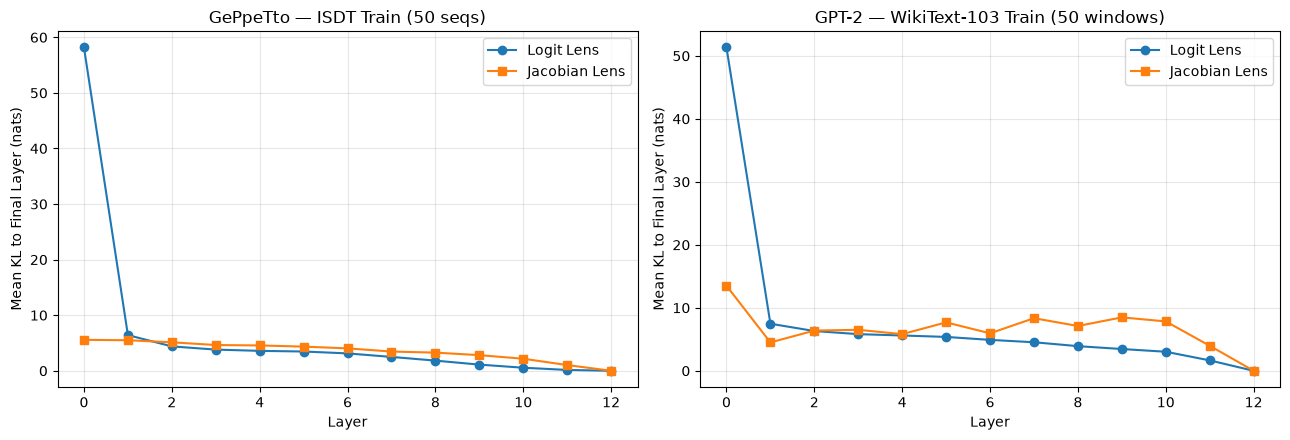

In [10]:
layers = list(range(len(geppetto_kl_logit)))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=False)

axes[0].plot(layers, geppetto_kl_logit, marker="o", label="Logit Lens")
axes[0].plot(layers, geppetto_kl_jac, marker="s", label="Jacobian Lens")
axes[0].set_title("GePpeTto — ISDT Train (50 seqs)")
axes[0].set_xlabel("Layer")
axes[0].set_ylabel("Mean KL to Final Layer (nats)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(layers, gpt2_kl_logit, marker="o", label="Logit Lens")
axes[1].plot(layers, gpt2_kl_jac, marker="s", label="Jacobian Lens")
axes[1].set_title("GPT-2 — WikiText-103 Train (50 windows)")
axes[1].set_xlabel("Layer")
axes[1].set_ylabel("Mean KL to Final Layer (nats)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()